In [20]:
import matplotlib.pyplot as plt
import numpy as np
import json

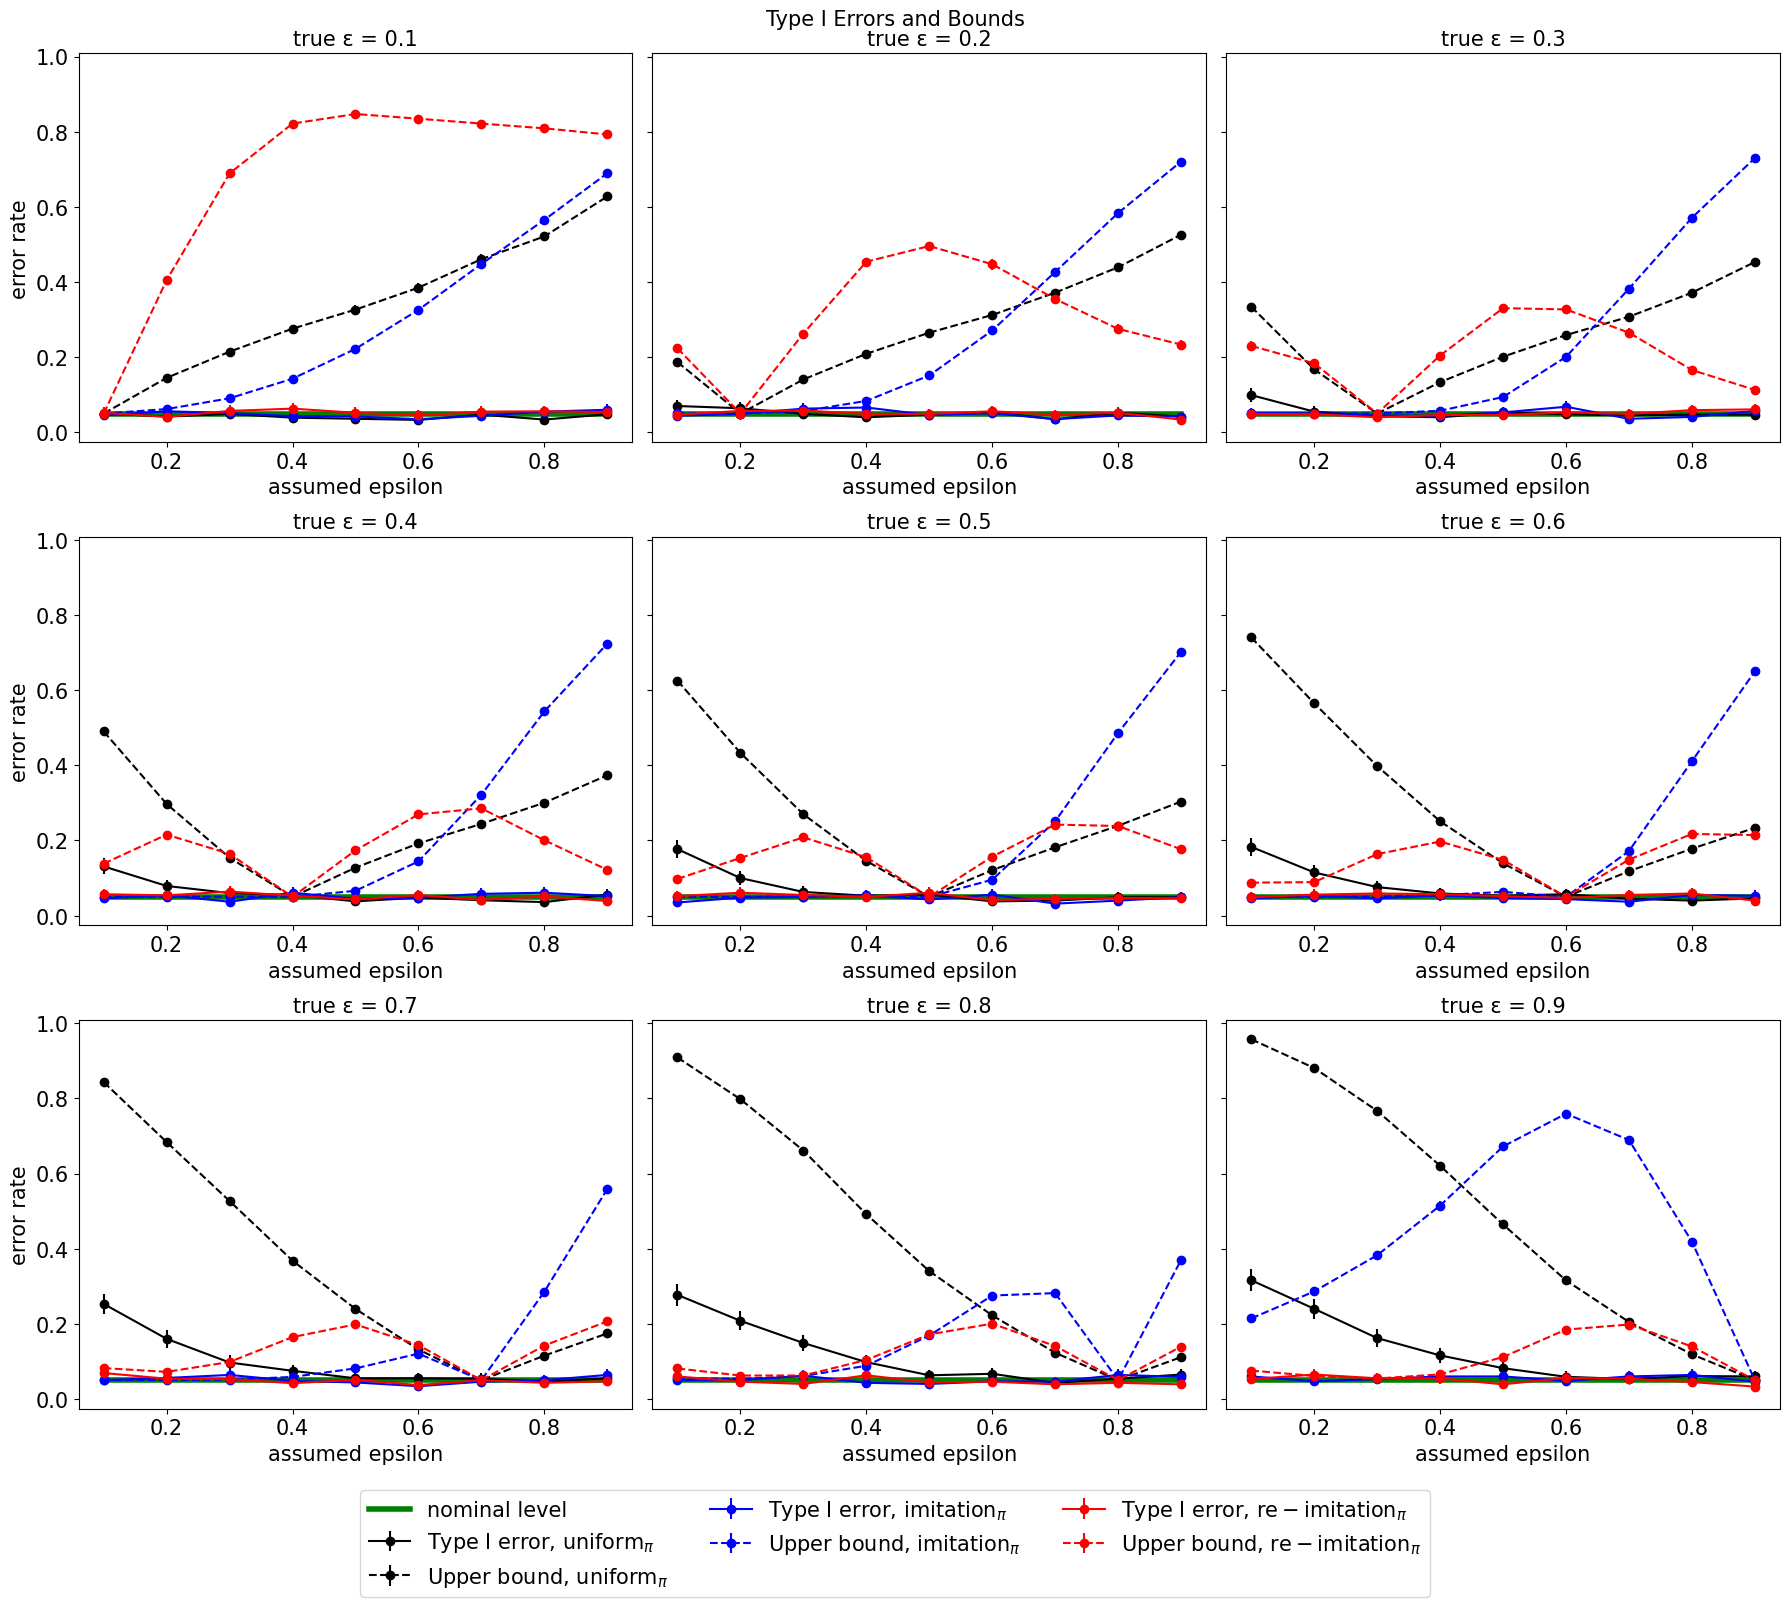

In [29]:
prefix = './collated_robustness_results/'

epsilons = np.linspace(0.1, 0.9, 9)

fig, axes = plt.subplots(3, 3, figsize=(18, 15), sharey=True)
axes_flat = axes.flatten()

for idx, true_eps in enumerate(epsilons):
    ax = axes_flat[idx]
    for style in ['u', 'i', 'r']:
        type_i_errs = []
        type_i_err_sds = []
        ubs = []
        ub_sds = []

        for analysis_eps in epsilons:
            results = json.load(open(prefix + f'egreedy_{style}_{analysis_eps}_{true_eps}', 'r'))
            type_i_errs.append(results[0])
            type_i_err_sds.append(results[1])
            ubs.append(results[2])
            ub_sds.append(results[3])

        if style == 'u':
            method = r'$\mathrm{uniform}_{\pi}$'
            col = 'black'
        if style == 'i':
            method = r'$\mathrm{imitation}_{\pi}$'
            col = 'blue'
        if style == 'r':
            method = r'$\mathrm{re-imitation}_{\pi}$'
            col = 'red'

        ax.errorbar(epsilons, type_i_errs, yerr=2 * np.array(type_i_err_sds),
                    color=col, marker='o', fmt="-", label=f'Type I error, ' + method)
        ax.errorbar(epsilons, ubs, yerr=2 * np.array(ub_sds),
                    color=col, marker='o', fmt="--", label=f'Upper bound, ' + method)

    ax.plot(epsilons, [0.05] * len(epsilons), label='nominal level', color='green', linewidth=4)
    ax.set_xlabel("assumed epsilon", fontsize=15)
    ax.set_title(f"true ε = {np.round(true_eps, decimals=2)}", fontsize=15)
    if idx % 3 == 0:
        ax.set_ylabel("error rate",fontsize=15)
    ax.tick_params(axis='both', labelsize=15)

# Single shared legend outside the grid
handles, labels = axes_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.),
           ncol=3, fontsize=15)

fig.suptitle("Type I Errors and Bounds", fontsize=15)
plt.tight_layout()
plt.show()